# Austin, Texas (open source) – EDA and Preprocessing

In [41]:
import os
from math import sqrt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [42]:
plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)

## 1. Load the raw dataset

In [43]:
NAME = "Austin"
DATA_PATH = "open_source_austin_daily_waste_2003_jan_2021_jul.csv"
raw = pd.read_csv(DATA_PATH)

In [44]:
print(raw.shape)

(5591, 2)


In [45]:
raw.head(10)

,ticket_date,net_weight_kg
0,2003-01-13,20170.0
1,2004-08-25,139140.0
2,2004-08-26,61480.0
3,2004-08-30,13160.0
4,2004-09-28,120740.0
5,2004-09-29,102600.0
6,2004-09-30,134520.0
7,2004-10-01,869869.0
8,2004-10-02,440.0
9,2004-10-03,0.0


In [46]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5591 entries, 0 to 5590
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ticket_date    5591 non-null   object 
 1   net_weight_kg  5591 non-null   float64
dtypes: float64(1), object(1)
memory usage: 87.5+ KB


In [47]:
raw.describe()

,net_weight_kg
count,5.591000e+03
mean,1.406606e+06
std,7.805302e+05
min,0.000000e+00
25%,1.356930e+06
50%,1.638680e+06
75%,1.891442e+06
max,3.745180e+06


In [48]:
print("Missing values per column:\n", raw.isna().sum())

Missing values per column:
 ticket_date      0
net_weight_kg    0
dtype: int64


In [49]:
print("\nExact duplicate rows:", raw.duplicated().sum())


Exact duplicate rows: 0


In [50]:
print("Zero-weight rows:", (raw["net_weight_kg"] == 0).sum(), "| negative:", (raw["net_weight_kg"] < 0).sum())

Zero-weight rows: 303 | negative: 0


In [51]:
dup_dates = raw[raw["ticket_date"].duplicated(keep=False)]

In [52]:
print("Dates with more than one reading:", dup_dates["ticket_date"].nunique())
dup_dates

Dates with more than one reading: 0


,ticket_date,net_weight_kg


## 2. Fix the day/month swap (per year)

In [53]:
iso = pd.to_datetime(raw["ticket_date"], format="%Y-%m-%d")
ydm = pd.to_datetime(raw["ticket_date"], format="%Y-%d-%m", errors="coerce")
ambiguous = (iso.dt.day <= 12) & (iso.dt.day != iso.dt.month)
kg = raw["net_weight_kg"]
reference = kg[~ambiguous].groupby(iso[~ambiguous]).sum()

In [54]:
def same_weekday_deviation(dates, mask):
    totals = kg[mask].groupby(dates[mask]).sum()
    devs = []
    for day, value in totals.items():
        neighbours = reference.reindex([day + pd.Timedelta(weeks=k) for k in (-3, -2, -1, 1, 2, 3)]).dropna()
        if len(neighbours) >= 2 and neighbours.median() > 0:
            devs.append(abs(value - neighbours.median()) / neighbours.median())
    return np.median(devs) if devs else np.nan

def weekend_ratio(dates, mask):
    d = kg[mask].groupby(dates[mask]).sum()
    p = d.groupby(d.index.dayofweek).mean()
    return p.reindex([5, 6]).mean() / p.reindex(range(5)).mean()

year_str = raw["ticket_date"].str[:4]
rows = []
for y in sorted(year_str.unique()):
    m = (year_str == y) & ambiguous
    dev_iso, dev_ydm = same_weekday_deviation(iso, m), same_weekday_deviation(ydm, m)
    rows.append({"year": y, "ambiguous rows": int(m.sum()),
                 "weekend ratio (day>12)": weekend_ratio(iso, (year_str == y) & ~ambiguous),
                 "weekend ratio as stored": weekend_ratio(iso, m),
                 "weekend ratio swapped": weekend_ratio(ydm, m),
                 "deviation as stored": dev_iso, "deviation swapped": dev_ydm,
                 "swap": bool(dev_ydm < dev_iso)})
swap_test = pd.DataFrame(rows).set_index("year")
swap_test.round(3)

,ambiguous rows,weekend ratio (day>12),weekend ratio as stored,weekend ratio swapped,deviation as stored,deviation swapped,swap
year,,,,,,,
2003,0,NaN,NaN,NaN,NaN,NaN,False
2004,33,0.074,0.002,1.184,0.094,0.116,False
2005,132,0.017,0.024,1.136,0.071,0.270,False
2006,132,0.053,0.008,1.255,0.077,0.366,False
2007,132,0.047,0.038,0.972,0.056,0.194,False
2008,132,0.050,0.042,0.855,0.057,0.215,False
2009,128,0.029,0.043,1.032,0.056,0.203,False
2010,117,0.017,0.055,1.183,0.065,0.172,False
2011,111,0.018,0.084,1.040,0.045,0.183,False


In [55]:
SWAP_YEARS = swap_test.index[swap_test["swap"]].tolist()
print("Years where day <= 12 dates are swapped:", SWAP_YEARS)
print("Years kept as stored:", swap_test.index[~swap_test["swap"]].tolist())

raw["ticket_date_original"] = raw["ticket_date"]
raw["date_swapped"] = ambiguous & year_str.isin(SWAP_YEARS)
raw["ticket_date"] = iso.where(~raw["date_swapped"], ydm)

print("Rows with swapped date:", int(raw["date_swapped"].sum()))
print("Duplicate keys after fix:", raw.duplicated(["ticket_date", "waste_type"] if "waste_type" in raw else ["ticket_date"]).sum())
print("Date range after fix:", raw["ticket_date"].min().date(), "to", raw["ticket_date"].max().date())

Years where day <= 12 dates are swapped: []
Years kept as stored: ['2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021']
Rows with swapped date: 0
Duplicate keys after fix: 0
Date range after fix: 2003-01-13 to 2021-07-09


## 3. EDA on the corrected daily series

In [56]:
daily = raw.groupby("ticket_date")["net_weight_kg"].mean()      # duplicate readings of the same day are averaged
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = full_range.difference(daily.index)

print("Days with data:", len(daily), "| calendar days:", len(full_range), "| missing days:", len(missing_days))
print("Missing days per year:", pd.Series(missing_days.year).value_counts().sort_index().to_dict())
daily.describe()

Days with data: 5591 | calendar days: 6753 | missing days: 1162
Missing days per year: {2003: 352, 2004: 271, 2005: 4, 2006: 1, 2007: 5, 2008: 1, 2009: 18, 2010: 49, 2011: 50, 2012: 41, 2013: 43, 2014: 43, 2015: 37, 2016: 49, 2017: 41, 2018: 49, 2019: 42, 2020: 42, 2021: 24}


,net_weight_kg
count,5.591000e+03
mean,1.406606e+06
std,7.805302e+05
min,0.000000e+00
25%,1.356930e+06
50%,1.638680e+06
75%,1.891442e+06
max,3.745180e+06


In [57]:
# Days present per year x month
present = pd.Series(daily.index)
present.groupby([present.dt.year, present.dt.month]).size().unstack(fill_value=0)

ticket_date,1,2,3,4,5,6,7,8,9,10,11,12
ticket_date,,,,,,,,,,,,
2003,1,0,0,0,0,0,0,0,0,0,0,0
2004,0,0,0,0,0,0,0,3,3,29,30,30
2005,30,28,31,30,31,30,31,31,30,31,29,29
2006,31,28,31,30,31,30,31,31,30,31,30,30
2007,28,28,31,30,31,30,31,31,30,31,29,30
2008,31,29,31,30,31,30,31,31,30,31,30,30
2009,31,28,31,30,31,30,31,27,27,28,27,26
2010,27,25,28,26,26,27,27,26,26,26,26,26
2011,26,23,28,26,26,26,26,27,27,27,26,27


In [58]:
# Longest runs of missing days
gaps = pd.Series(missing_days)
run_id = (gaps.diff().dt.days != 1).cumsum()
runs = gaps.groupby(run_id).agg(start="min", end="max", length="count")
runs.sort_values("length", ascending=False).head(10)

,start,end,length
1,2003-01-14,2004-08-24,589
3,2004-08-31,2004-09-27,28
523,2021-02-13,2021-02-18,6
2,2004-08-27,2004-08-29,3
384,2017-12-24,2017-12-25,2
385,2017-12-31,2018-01-01,2
12,2007-01-16,2007-01-17,2
82,2010-12-25,2010-12-26,2
355,2017-03-05,2017-03-05,1
356,2017-04-02,2017-04-02,1


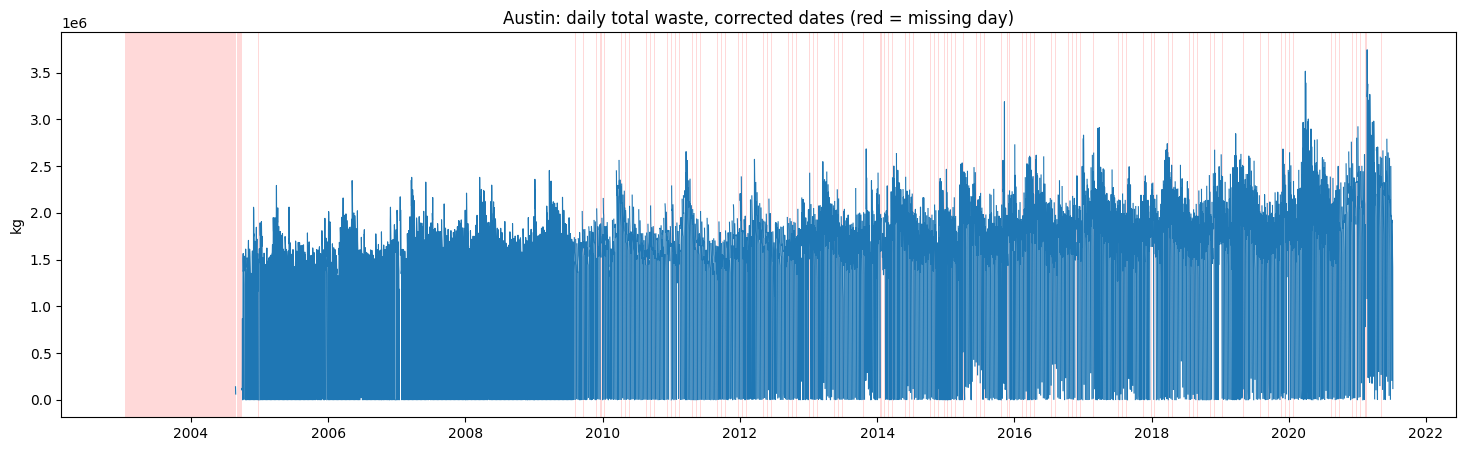

In [59]:
s = daily.reindex(full_range)
fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=0.8)
for d in missing_days:
    ax.axvspan(d, d + pd.Timedelta(days=1), color="red", alpha=0.15, lw=0)
ax.set_title(f"{NAME}: daily total waste, corrected dates (red = missing day)")
ax.set_ylabel("kg")
plt.show()

In [60]:
dd = daily.to_frame("kg")
dd["weekday"] = dd.index.day_name()
dd["month"] = dd.index.month
dd["year"] = dd.index.year
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

display(dd.groupby("weekday")["kg"].agg(["mean", "median", "count"]).reindex(order).round(0))
display(dd.groupby("month")["kg"].agg(["mean", "median", "count"]).round(0))
display(dd.groupby("year")["kg"].agg(["mean", "median", "count"]).round(0))

,mean,median,count
weekday,,,
Monday,2018413.0,1986190.0,873
Tuesday,1707282.0,1683480.0,867
Wednesday,1878009.0,1853623.0,873
Thursday,1741933.0,1749131.0,869
Friday,1552568.0,1547410.0,870
Saturday,128760.0,7920.0,869
Sunday,16692.0,0.0,370


,mean,median,count
month,,,
1,1456367.0,1688632.0,470
2,1352282.0,1570980.0,433
3,1503706.0,1767308.0,505
4,1559173.0,1850711.0,471
5,1492669.0,1745660.0,477
6,1434596.0,1658018.0,466
7,1337786.0,1558120.0,459
8,1310996.0,1523360.0,449
9,1310217.0,1552432.0,440


,mean,median,count
year,,,
2003,20170.0,20170.0,1
2004,1045751.0,1408320.0,95
2005,1102528.0,1428590.0,361
2006,1133285.0,1441790.0,364
2007,1223448.0,1591834.0,360
2008,1235136.0,1597754.0,365
2009,1295683.0,1619810.0,347
2010,1443883.0,1668154.0,316
2011,1410344.0,1616040.0,315


/tmp/ipykernel_1398/2084828194.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([dd.loc[dd["weekday"] == d, "kg"] for d in present_days], labels=[d[:3] for d in present_days])
/tmp/ipykernel_1398/2084828194.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([dd.loc[dd["month"] == m, "kg"] for m in range(1, 13)], labels=list(range(1, 13)))


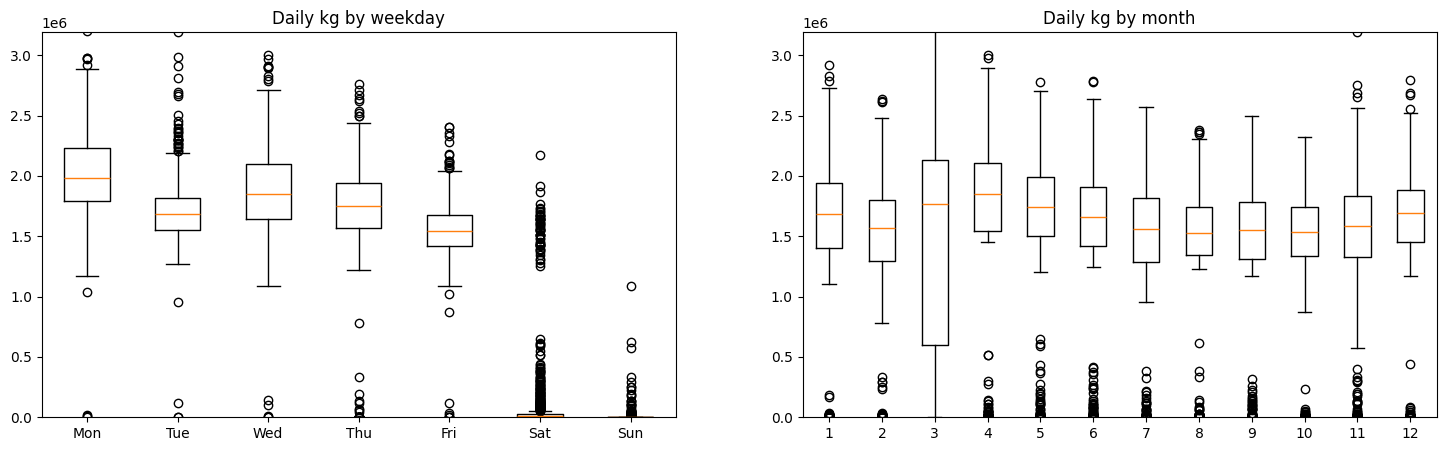

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
present_days = [d for d in order if (dd["weekday"] == d).any()]
axes[0].boxplot([dd.loc[dd["weekday"] == d, "kg"] for d in present_days], labels=[d[:3] for d in present_days])
axes[0].set_title("Daily kg by weekday")
axes[1].boxplot([dd.loc[dd["month"] == m, "kg"] for m in range(1, 13)], labels=list(range(1, 13)))
axes[1].set_title("Daily kg by month")
upper = dd["kg"].quantile(0.99) * 1.2
for a in axes:
    a.set_ylim(0, upper)
plt.show()

## 4. Preprocessing

### 4.1 Calendar days

In [62]:
START = pd.Timestamp("2005-01-01")
END = pd.Timestamp("2011-12-31")

prep = daily.reindex(pd.date_range(START, END, freq="D")).to_frame("net_weight_kg")
prep.index.name = "ticket_date"
prep["net_weight_kg_raw"] = prep["net_weight_kg"]
prep["is_weekend"] = prep.index.dayofweek >= 5
prep["is_missing"] = prep["net_weight_kg_raw"].isna()

print("Calendar:", START.date(), "to", END.date(), "|", len(prep), "days")
print("Days with recorded values:", int((~prep["is_missing"]).sum()), "| missing days:", int(prep["is_missing"].sum()))
last_in_range = prep.index[~prep["is_missing"]].max()
print("Last recorded day in range:", last_in_range.date(), "| days after it up to END:", int((prep.index > last_in_range).sum()))

Calendar: 2005-01-01 to 2011-12-31 | 2556 days
Days with recorded values: 2428 | missing days: 128
Last recorded day in range: 2011-12-31 | days after it up to END: 0


### 4.2 Closure days (no collection)

In [63]:
from dateutil.easter import easter

HOLIDAYS = ['new_year', 'thanksgiving', 'christmas']

def holiday_dates(years):
    days = []
    for y in years:
        if "new_year" in HOLIDAYS:
            days.append(pd.Timestamp(y, 1, 1))
        if "christmas" in HOLIDAYS:
            days.append(pd.Timestamp(y, 12, 25))
        if "good_friday" in HOLIDAYS:
            days.append(pd.Timestamp(easter(y)) - pd.Timedelta(days=2))
        if "thanksgiving" in HOLIDAYS:                     # 4th Thursday of November
            nov1 = pd.Timestamp(y, 11, 1)
            days.append(nov1 + pd.Timedelta(days=(3 - nov1.dayofweek) % 7 + 21))
    return pd.DatetimeIndex(days)

dow_stats = pd.DataFrame({
    "recorded_share": prep["net_weight_kg_raw"].notna().groupby(prep.index.dayofweek).mean(),
    "median_kg": prep["net_weight_kg_raw"].groupby(prep.index.dayofweek).median(),
})
dow_stats.index = order
dow_stats["closed"] = (dow_stats["recorded_share"] < 0.5) | (dow_stats["median_kg"].fillna(0) == 0)
display(dow_stats.round(2))
CLOSED_DOW = [i for i, c in enumerate(dow_stats["closed"]) if c]

hol = holiday_dates(range(START.year, END.year + 1))
hol = hol[(hol >= START) & (hol <= END)]
display(pd.DataFrame({"recorded_kg": prep["net_weight_kg_raw"].reindex(hol)}, index=hol))

,recorded_share,median_kg,closed
Monday,1.00,1790752.0,False
Tuesday,0.99,1717420.0,False
Wednesday,1.00,1636643.0,False
Thursday,0.99,1576359.0,False
Friday,0.99,1534280.0,False
Saturday,0.99,6440.0,False
Sunday,0.68,0.0,True


,recorded_kg
2005-01-01,NaN
2005-12-25,NaN
2005-11-24,NaN
2006-01-01,0.0
2006-12-25,NaN
2006-11-23,0.0
2007-01-01,0.0
2007-12-25,NaN
2007-11-22,NaN
2008-01-01,0.0


In [64]:
prep["is_closure_day"] = prep.index.dayofweek.isin(CLOSED_DOW) | prep.index.isin(hol)
prep["is_closure_zero"] = prep["is_closure_day"] & prep["is_missing"]
prep.loc[prep["is_closure_zero"], "net_weight_kg"] = 0

print("Closed days of the week:", [order[i] for i in CLOSED_DOW])
print("Closure days in calendar:", int(prep["is_closure_day"].sum()),
      "| missing closure days set to 0:", int(prep["is_closure_zero"].sum()))
print("Missing operating days left to impute:", int((prep["is_missing"] & ~prep["is_closure_day"]).sum()))

Closed days of the week: ['Sunday']
Closure days in calendar: 383 | missing closure days set to 0: 125
Missing operating days left to impute: 3


### 4.3 Weekly pattern on operating days

In [65]:
obs = prep.loc[~prep["is_missing"], "net_weight_kg"]
obs.groupby(obs.index.day_name()).agg(["mean", "median", "count"]).reindex(order).round(0)

,mean,median,count
ticket_date,,,
Monday,1799981.0,1790752.0,364
Tuesday,1717239.0,1717420.0,363
Wednesday,1663504.0,1636643.0,364
Thursday,1575240.0,1576359.0,362
Friday,1537637.0,1534280.0,363
Saturday,108119.0,6440.0,364
Sunday,411.0,0.0,248


### 4.4 Outlier detection (same-weekday comparison)

In [66]:
Z_THRESHOLD = 3.5

local_med = pd.Series(np.nan, index=prep.index)
local_mad = pd.Series(np.nan, index=prep.index)
operating = prep["net_weight_kg"].where(~prep["is_closure_day"])    # closure days are not judged
for dow in range(7):
    s = operating[prep.index.dayofweek == dow]
    med = s.rolling(7, center=True, min_periods=3).median()
    local_med.loc[s.index] = med
    local_mad.loc[s.index] = (s - med).abs().rolling(7, center=True, min_periods=3).median()

prep["robust_z"] = 0.6745 * (operating - local_med) / local_mad.replace(0, np.nan)
prep["is_outlier"] = prep["robust_z"].abs() > Z_THRESHOLD
print("Outliers flagged:", int(prep["is_outlier"].sum()),
      "| on weekends:", int((prep["is_outlier"] & prep["is_weekend"]).sum()),
      f"| {prep['is_outlier'].sum() / prep['robust_z'].notna().sum() * 100:.1f} % of judged days")

# Sensitivity: how many days each threshold would flag (choose Z_THRESHOLD from this, then re-run)
display(pd.DataFrame({"threshold": [3.0, 3.5, 5.0, 7.0],
                      "days flagged": [int((prep["robust_z"].abs() > t).sum()) for t in [3.0, 3.5, 5.0, 7.0]]}))
prep.loc[prep["is_outlier"], ["net_weight_kg_raw", "robust_z"]].assign(
    weekday=lambda x: x.index.day_name(), same_weekday_median=local_med[prep["is_outlier"]]).round(1)

Outliers flagged: 169 | on weekends: 53 | 8.0 % of judged days


,threshold,days flagged
0,3.0,198
1,3.5,169
2,5.0,100
3,7.0,77


,net_weight_kg_raw,robust_z,weekday,same_weekday_median
ticket_date,,,,
2005-01-13,1749428.0,3.5,Thursday,1399366.0
2005-03-31,2293598.0,127.2,Thursday,1799322.0
2005-04-01,1871893.0,94.4,Friday,1626888.0
2005-04-05,1939880.0,4.4,Tuesday,1812238.0
2005-04-07,2053464.0,65.4,Thursday,1799322.0
...,...,...,...,...
2011-10-01,9440.0,6.4,Saturday,5620.0
2011-11-26,1646080.0,182.6,Saturday,16580.0
2011-11-29,2048160.0,3.9,Tuesday,1791115.0


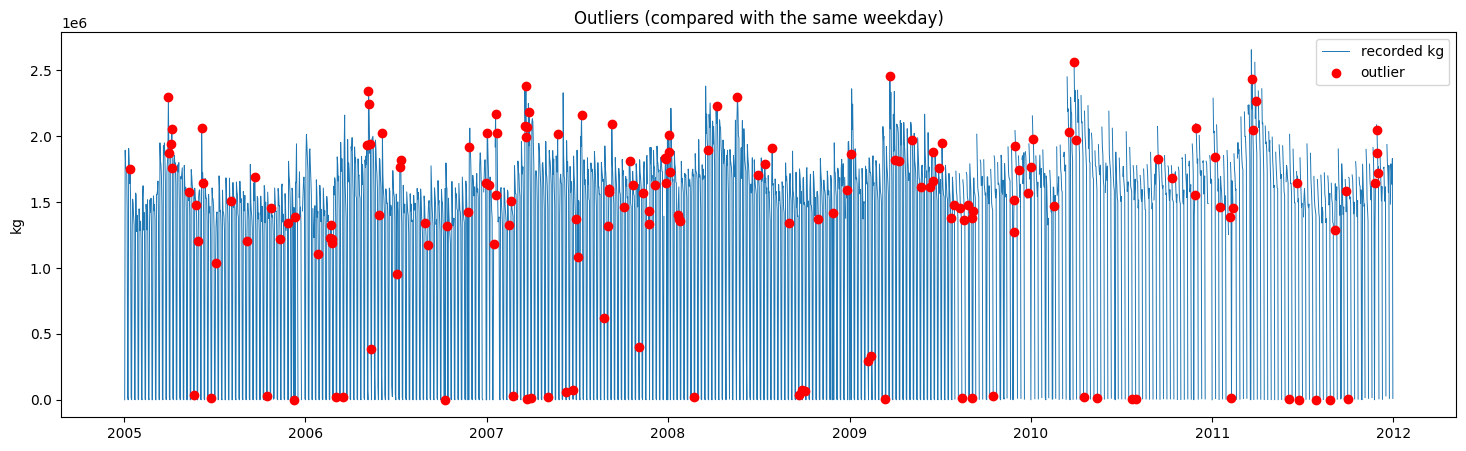

In [67]:
fig, ax = plt.subplots()
ax.plot(prep.index, prep["net_weight_kg_raw"], lw=0.7, label="recorded kg")
o = prep[prep["is_outlier"]]
ax.scatter(o.index, o["net_weight_kg_raw"], color="red", zorder=3, label="outlier")
ax.legend(); ax.set_ylabel("kg"); ax.set_title("Outliers (compared with the same weekday)")
plt.show()

In [68]:
# Outliers become gaps and are imputed together with the missing days
prep.loc[prep["is_outlier"], "net_weight_kg"] = np.nan
to_impute = prep["net_weight_kg"].isna()
print("Days to impute:", int(to_impute.sum()), f"({to_impute.mean() * 100:.1f} % of calendar days)",
      "| missing operating days:", int((prep["is_missing"] & ~prep["is_closure_zero"]).sum()),
      "| outliers:", int(prep["is_outlier"].sum()))

Days to impute: 172 (6.7 % of calendar days) | missing operating days: 3 | outliers: 169


### 4.5 Imputation with XGBoost

In [69]:
def make_features(series, lag_count):
    X = pd.DataFrame(index=series.index)
    X = pd.concat([X] + [series.shift(i).rename(f"lag_{i}") for i in range(1, lag_count + 1)], axis=1)
    X["dayofweek"] = series.index.dayofweek
    X["is_weekend"] = (series.index.dayofweek >= 5).astype(int)
    X["month"] = series.index.month
    return X

def splits(index):
    n = len(index)
    return index[: int(n * 0.6)], index[int(n * 0.6): int(n * 0.8)], index[int(n * 0.8):]

target = prep["net_weight_kg"]                 # gaps and outliers are NaN; missing closure days are 0
known_days = target.index[target.notna() & ~prep["is_closure_zero"]]    # real recorded days only
train_idx, val_idx, test_idx = splits(known_days)
print("train / val / test real days:", len(train_idx), len(val_idx), len(test_idx))
print("test period:", test_idx.min().date(), "to", test_idx.max().date())

train / val / test real days: 1355 452 452
test period: 2010-06-24 to 2011-12-31


In [70]:
lag_list = [7, 14, 28]
depth_list = [3, 5]
estimator_list = [200, 500]
eta_list = [0.03, 0.1]

results = []
for lag in lag_list:
    X = make_features(target, lag)
    for depth in depth_list:
        for n_est in estimator_list:
            for eta in eta_list:
                model = xgboost.XGBRegressor(n_estimators=n_est, max_depth=depth, learning_rate=eta,
                                             subsample=0.8, objective="reg:squarederror",
                                             random_state=0, n_jobs=-1)
                model.fit(X.loc[train_idx], target.loc[train_idx])
                pred = model.predict(X.loc[val_idx])
                results.append({"lag_count": lag, "max_depth": depth, "n_estimators": n_est, "eta": eta,
                                "val_rmse": sqrt(mean_squared_error(target.loc[val_idx], pred)),
                                "val_mae": mean_absolute_error(target.loc[val_idx], pred)})

results_df = pd.DataFrame(results).sort_values("val_rmse").reset_index(drop=True)
results_df.head(10)

,lag_count,max_depth,n_estimators,eta,val_rmse,val_mae
0,28,3,200,0.10,135465.401656,79827.856144
1,28,3,500,0.10,136426.736505,82552.963014
2,28,3,500,0.03,137401.035067,78240.807094
3,14,3,500,0.03,138124.199056,79489.781188
4,14,3,500,0.10,138928.514374,83357.793998
5,14,3,200,0.10,139167.979673,81317.942677
6,28,5,500,0.03,142509.441952,76165.854182
7,14,3,200,0.03,142557.806181,79407.900703
8,28,3,200,0.03,143034.406828,79546.713187
9,28,5,200,0.10,143342.929104,79223.857310


Best settings: {'lag_count': 28.0, 'max_depth': 3.0, 'n_estimators': 200.0, 'eta': 0.1, 'val_rmse': 135465.40165553862, 'val_mae': 79827.85614364759}
Test  XGBoost   RMSE 145,620 | MAE 77,367
Test  lag-7     RMSE 186,345 | MAE 96,740


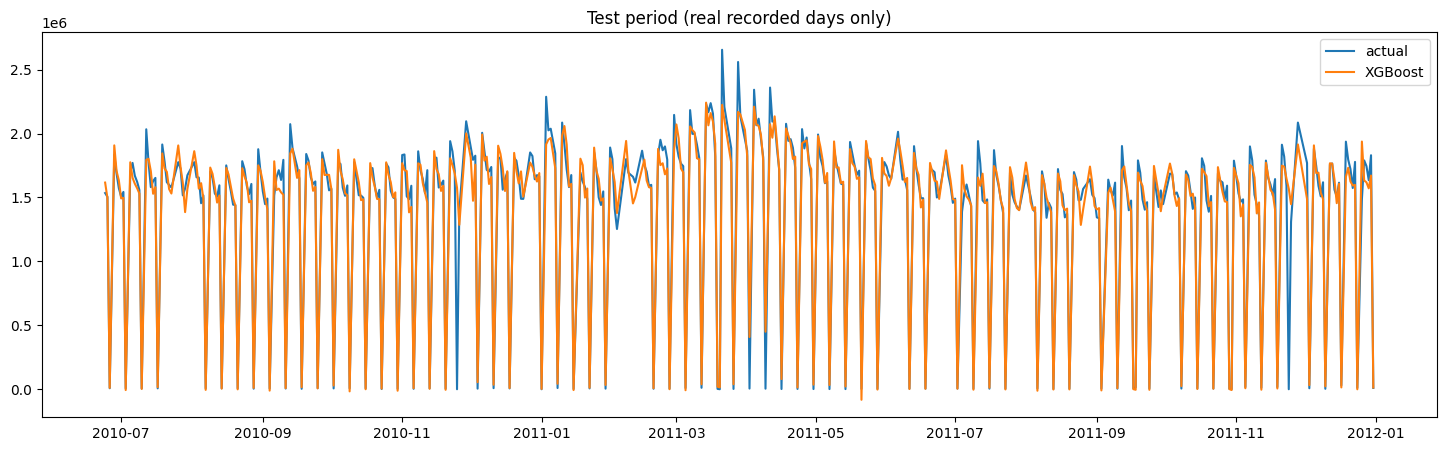

In [71]:
best = results_df.iloc[0]
LAG = int(best["lag_count"])
print("Best settings:", best.to_dict())

X = make_features(target, LAG)
fit_idx = train_idx.append(val_idx)
best_model = xgboost.XGBRegressor(n_estimators=int(best["n_estimators"]), max_depth=int(best["max_depth"]),
                                  learning_rate=float(best["eta"]), subsample=0.8,
                                  objective="reg:squarederror", random_state=0, n_jobs=-1)
best_model.fit(X.loc[fit_idx], target.loc[fit_idx])
test_pred = best_model.predict(X.loc[test_idx])

y_test = target.loc[test_idx]
baseline = target.shift(7).loc[test_idx]
ok = baseline.notna()
print(f"Test  XGBoost   RMSE {sqrt(mean_squared_error(y_test, test_pred)):,.0f} | MAE {mean_absolute_error(y_test, test_pred):,.0f}")
print(f"Test  lag-7     RMSE {sqrt(mean_squared_error(y_test[ok], baseline[ok])):,.0f} | MAE {mean_absolute_error(y_test[ok], baseline[ok]):,.0f}")

plt.plot(y_test.index, y_test.values, label="actual")
plt.plot(y_test.index, test_pred, label="XGBoost")
plt.title("Test period (real recorded days only)"); plt.legend(); plt.show()

In [72]:
# from tqdm.auto import tqdm

# full_grid = [(l, n, d, s, e) for l in [14, 42, 49, 90, 120, 150, 360] for n in [10, 100, 1000]
#              for d in [3, 4, 6, 7, 8, 9] for s in [0.6, 0.7, 0.8, 0.9] for e in [0.01, 0.1, 0.3]]
# small_grid = [(l, n, d, 0.8, e) for l in lag_list for n in estimator_list for d in depth_list for e in eta_list]

# feature_cache = {}
# def features(lag):
#     if lag not in feature_cache:
#         feature_cache[lag] = make_features(target, lag)
#     return feature_cache[lag]

# def search(grid, label):
#     best = None
#     for lag, n, d, s, e in tqdm(grid, desc=label, unit="model"):   # shows done / remaining / time left
#         X = features(lag)
#         m = xgboost.XGBRegressor(n_estimators=n, max_depth=d, subsample=s, learning_rate=e,
#                                  objective="reg:squarederror", random_state=0, n_jobs=-1)
#         m.fit(X.loc[train_idx], target.loc[train_idx])
#         rmse = sqrt(mean_squared_error(target.loc[val_idx], m.predict(X.loc[val_idx])))
#         if best is None or rmse < best[0]:
#             best = (rmse, lag, n, d, s, e)
#     rmse, lag, n, d, s, e = best
#     X = features(lag)
#     m = xgboost.XGBRegressor(n_estimators=n, max_depth=d, subsample=s, learning_rate=e,
#                              objective="reg:squarederror", random_state=0, n_jobs=-1)
#     m.fit(X.loc[fit_idx], target.loc[fit_idx])
#     err = target.loc[test_idx] - m.predict(X.loc[test_idx])
#     summary = {"configs": len(grid), "val_rmse": round(rmse), "test_rmse": round(sqrt((err ** 2).mean())),
#                "lag": lag, "n_estimators": n, "max_depth": d, "subsample": s, "eta": e}
#     return summary, err

# small, err_small = search(small_grid, f"Reduced grid ({len(small_grid)} models)")
# full, err_full = search(full_grid, f"Original grid ({len(full_grid)} models)")
# display(pd.DataFrame([small, full], index=["reduced grid", "original grid"]))

# # Bootstrap the test days: is the test RMSE difference real or noise?
# rng = np.random.default_rng(0)
# diffs = []
# for _ in range(2000):
#     i = rng.integers(0, len(err_small), len(err_small))
#     diffs.append(sqrt((err_small.iloc[i] ** 2).mean()) - sqrt((err_full.iloc[i] ** 2).mean()))
# lo, hi = np.percentile(diffs, [2.5, 97.5])
# print(f"Test RMSE difference (reduced - original): {small['test_rmse'] - full['test_rmse']:,} kg | "
#       f"95% CI [{lo:,.0f}, {hi:,.0f}] kg")

In [73]:
# Refit on all real days, then fill gaps in time order so later gaps can use earlier filled values
final_model = xgboost.XGBRegressor(n_estimators=int(best["n_estimators"]), max_depth=int(best["max_depth"]),
                                   learning_rate=float(best["eta"]), subsample=0.8,
                                   objective="reg:squarederror", random_state=0, n_jobs=-1)
final_model.fit(make_features(target, LAG).loc[known_days], target.loc[known_days])

filled = target.copy()
for day in filled.index[filled.isna()]:
    pos = filled.index.get_loc(day)
    row = {f"lag_{i}": (filled.iloc[pos - i] if pos - i >= 0 else np.nan) for i in range(1, LAG + 1)}
    row["dayofweek"] = day.dayofweek
    row["is_weekend"] = int(day.dayofweek >= 5)
    row["month"] = day.month
    filled.loc[day] = max(float(final_model.predict(pd.DataFrame([row]))[0]), 0.0)

prep["is_imputed"] = prep["net_weight_kg"].isna()
prep["net_weight_kg"] = filled

imp = prep.loc[prep["is_imputed"], "net_weight_kg"]
print("Imputed values:", len(imp), f"({len(imp) / len(prep) * 100:.2f} % of all days)")
real = prep.loc[~prep["is_imputed"] & ~prep["is_closure_zero"], "net_weight_kg"]
print(f"Mean imputed: {imp.mean():,.0f} kg | mean recorded: {real.mean():,.0f} kg")
print("Imputed per weekday:", prep.loc[prep["is_imputed"]].index.day_name().value_counts().reindex(order, fill_value=0).to_dict())
print("Blanks left:", int(prep["net_weight_kg"].isna().sum()))

Imputed values: 172 (6.73 % of all days)
Mean imputed: 1,171,839 kg | mean recorded: 1,250,398 kg
Imputed per weekday: {'Monday': 27, 'Tuesday': 23, 'Wednesday': 20, 'Thursday': 24, 'Friday': 25, 'Saturday': 53, 'Sunday': 0}
Blanks left: 0


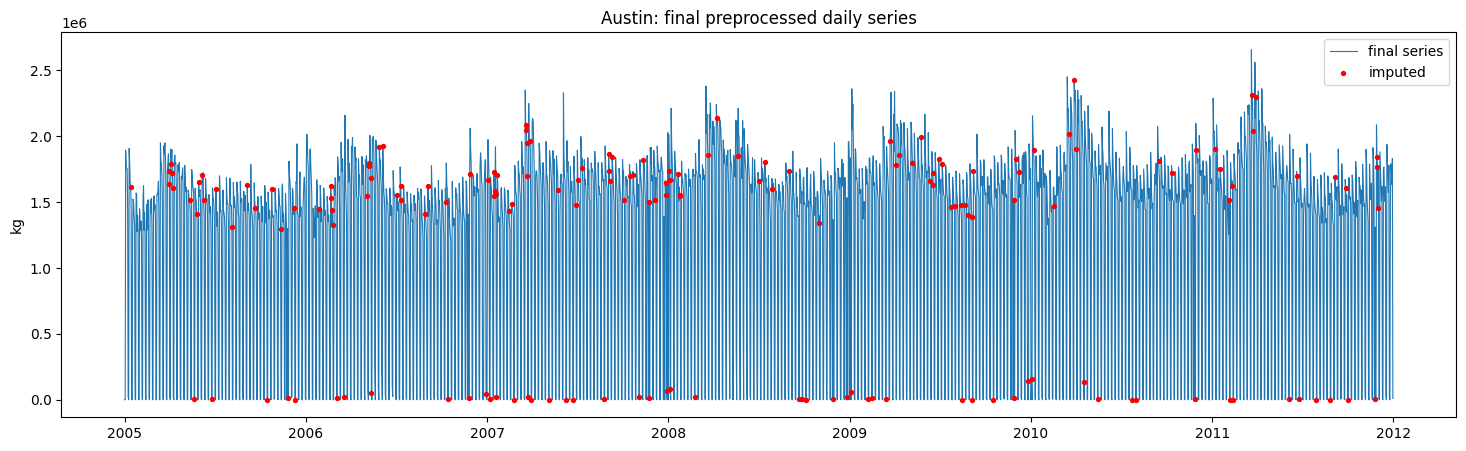

In [74]:
fig, ax = plt.subplots()
ax.plot(prep.index, prep["net_weight_kg"], lw=0.8, label="final series")
i = prep[prep["is_imputed"]]
ax.scatter(i.index, i["net_weight_kg"], s=8, color="red", zorder=3, label="imputed")
ax.set_title(f"{NAME}: final preprocessed daily series"); ax.set_ylabel("kg"); ax.legend()
plt.show()

### 4.6 Export

In [75]:
raw.columns

Index(['ticket_date', 'net_weight_kg', 'ticket_date_original', 'date_swapped'], dtype='object')

In [76]:
OUT_PATH = "daily_waste_output_austin_datefixed.csv"
DETAILS_PATH = "daily_waste_output_austin_datefixed_details.csv"

In [77]:
out = prep.reset_index()[["ticket_date", "net_weight_kg"]]

In [78]:
out.head(5)

,ticket_date,net_weight_kg
0,2005-01-01,0.0
1,2005-01-02,0.0
2,2005-01-03,1892964.0
3,2005-01-04,1760295.0
4,2005-01-05,1754280.0


In [79]:
out.to_csv(OUT_PATH, index=False)
print("Saved model input:", OUT_PATH, out.shape)

Saved model input: daily_waste_output_austin_datefixed.csv (2556, 2)


In [80]:
details = prep.reset_index()[["ticket_date", "net_weight_kg", "net_weight_kg_raw",
                          "is_weekend", "is_missing", "is_closure_zero", "is_outlier", "is_imputed"]]
details.to_csv(DETAILS_PATH, index=False)
print("Saved:", DETAILS_PATH, out.shape)


Saved: daily_waste_output_austin_datefixed_details.csv (2556, 2)


In [81]:
details.head()

,ticket_date,net_weight_kg,net_weight_kg_raw,is_weekend,is_missing,is_closure_zero,is_outlier,is_imputed
0,2005-01-01,0.0,NaN,True,True,True,False,False
1,2005-01-02,0.0,0.0,True,False,False,False,False
2,2005-01-03,1892964.0,1892964.0,False,False,False,False,False
3,2005-01-04,1760295.0,1760295.0,False,False,False,False,False
4,2005-01-05,1754280.0,1754280.0,False,False,False,False,False


In [82]:
details.head()

,ticket_date,net_weight_kg,net_weight_kg_raw,is_weekend,is_missing,is_closure_zero,is_outlier,is_imputed
0,2005-01-01,0.0,NaN,True,True,True,False,False
1,2005-01-02,0.0,0.0,True,False,False,False,False
2,2005-01-03,1892964.0,1892964.0,False,False,False,False,False
3,2005-01-04,1760295.0,1760295.0,False,False,False,False,False
4,2005-01-05,1754280.0,1754280.0,False,False,False,False,False
